# 13. Ensembles e ensembles de híbridos

Um ensemble combina **previsões de candidatas completas** — modelos isolados, híbridos residuais ou outros ensembles. Este notebook cobre a F2 do plano de ensembles:

1. agregações simples e ponderadas (`equal`, `median`, `trimmed_mean`, `inverse_mse`, `nnls`);
2. ensemble de híbridos e ensemble corrigido por um corretor residual;
3. ensembles na busca automática, com a regra de aceite decidindo se valem a complexidade.

Os controles são o melhor modelo isolado e a média simples: um ensemble mais elaborado precisa superá-los nas mesmas origens. Pesos aprendidos usam só o vetor de treino de cada origem (previsões fora da amostra de um passo).

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def clean(ax, grid_axis="both"):
    """Recessive grid and axes; text in neutral ink."""
    ax.grid(axis=grid_axis, color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#52514e")


print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Dados e controles

In [2]:
y = get_data("synthetic_daily", n=500)
exp = AutoHybridExperiment(fh=14, fold=3, session_id=42).fit(y)


def summary(result, name=None):
    frame = result.evaluation.to_frame()
    return {
        "candidata": name or result.candidate.name,
        "MASE V_search": frame.loc[frame["layer"] == "search", "MASE"].mean(),
        "MASE V_select": frame.loc[frame["layer"] == "select", "MASE"].mean(),
        "ajustes/origem": result.evaluation.trials[0].n_fits,
    }


members = {name: exp.create_model(name) for name in ["seasonal_naive", "linear", "knn"]}
pd.DataFrame([summary(m) for m in members.values()]).set_index("candidata").round(3)

,MASE V_search,MASE V_select,ajustes/origem
candidata,,,
seasonal_naive,1.288,1.522,1
linear,1.222,1.277,1
knn,0.997,1.827,1


## 2. Agregações

Os mesmos três membros, cinco formas de combinar. `nnls` encolhe os pesos para a média (`shrinkage=0.5`): com poucas linhas fora da amostra, pesos livres oscilam.

In [3]:
ensembles = {
    method: exp.create_ensemble(list(members.values()), method=method)
    for method in ["equal", "median", "trimmed_mean", "inverse_mse", "nnls"]
}
pd.DataFrame([summary(r, f"{m}") for m, r in ensembles.items()]).set_index("candidata").round(3)

,MASE V_search,MASE V_select,ajustes/origem
candidata,,,
equal,1.093,1.496,3
median,1.153,1.507,3
trimmed_mean,1.153,1.507,3
inverse_mse,1.176,1.341,6
nnls,1.122,1.391,6


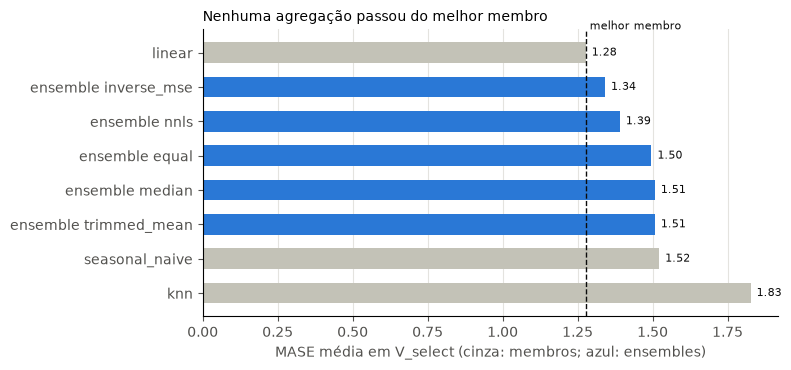

In [4]:
scores = (
    pd.DataFrame(
        [summary(m) for m in members.values()]
        + [summary(r, f"ensemble {m}") for m, r in ensembles.items()]
    )
    .set_index("candidata")["MASE V_select"]
    .sort_values(ascending=False)
)
best_member = min(summary(m)["MASE V_select"] for m in members.values())
fig, ax = plt.subplots(figsize=(8, 3.8))
is_ensemble = scores.index.str.startswith("ensemble")
ax.barh(
    scores.index,
    scores,
    color=["#2a78d6" if flag else "#c3c2b7" for flag in is_ensemble],
    height=0.6,
)
for row, value in enumerate(scores):
    ax.text(value + 0.02, row, f"{value:.2f}", va="center", fontsize=8, color="#0b0b0b")
ax.axvline(best_member, color="#0b0b0b", linewidth=1, linestyle="--")
ax.text(
    best_member,
    len(scores) - 0.4,
    " melhor membro",
    fontsize=8,
    color="#0b0b0b",
    va="bottom",
)
ax.set_xlabel("MASE média em V_select (cinza: membros; azul: ensembles)", color="#52514e")
ax.set_title("Nenhuma agregação passou do melhor membro", loc="left", fontsize=10)
clean(ax, grid_axis="x")
fig.tight_layout()

Pesos aprendidos em cada origem, por membro. Ver pesos mudarem entre origens é sinal de instabilidade, não de sabedoria; a linha tracejada é a média simples.

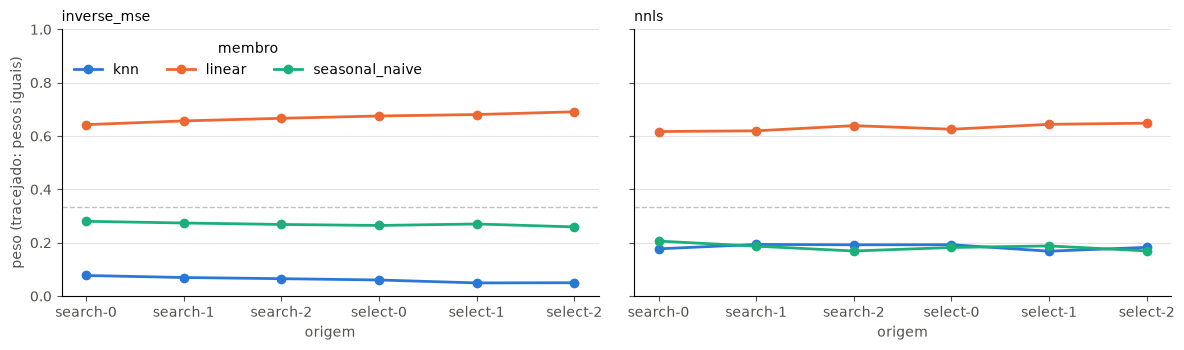

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
member_colors = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed order of the components
for ax, method in zip(axes, ["inverse_mse", "nnls"], strict=True):
    result = ensembles[method]
    names = [component.name for component in result.candidate.components]
    trials = result.evaluation.trials
    origins = [t.fold_id for t in trials]
    for k, (name, color) in enumerate(zip(names, member_colors, strict=True)):
        values = [t.diagnostics[f"weight_{k}"] for t in trials]
        ax.plot(origins, values, marker="o", color=color, linewidth=2, label=name)
    ax.axhline(1 / len(names), color="#c3c2b7", linewidth=1, linestyle="--")
    ax.set_title(f"{method}", loc="left", fontsize=10)
    ax.set_xlabel("origem", color="#52514e")
    ax.set_ylim(0, 1)
    clean(ax, grid_axis="y")
axes[0].set_ylabel("peso (tracejado: pesos iguais)", color="#52514e")
axes[0].legend(frameon=False, title="membro", loc="upper left", ncol=3)
fig.tight_layout()

## 3. Ensemble de híbridos e ensemble corrigido

* **Ensemble de híbridos:** combina híbridos independentes; só ajuda se as correções forem complementares.
* **Ensemble corrigido:** um corretor aprende os resíduos fora da amostra **do ensemble**, não a soma de resíduos de cada membro.

In [6]:
hybrids = [
    exp.create_hybrid("seasonal_naive", "linear", window=14),
    exp.create_hybrid("linear", "knn", window=14),
]
of_hybrids = exp.create_ensemble(hybrids, method="nnls")
corrected = exp.create_hybrid(ensembles["equal"], "linear", window=14)
rows = [summary(h) for h in hybrids] + [summary(of_hybrids), summary(corrected)]
pd.DataFrame(rows).set_index("candidata").round(3)

,MASE V_search,MASE V_select,ajustes/origem
candidata,,,
seasonal_naive-linear,0.949,1.409,3
linear-knn,1.310,1.339,3
"nnls[linear-knn,seasonal_naive-linear]",1.047,1.325,12
"(equal[knn,linear,seasonal_naive])-linear",1.128,1.643,7


## 4. Ensembles na busca automática

Com `include=(..., "ensemble")`, a etapa S4 propõe ensembles das melhores bases de famílias diferentes, das duas melhores estruturas residuais e o ensemble de pesos iguais corrigido. A família `ensemble` desafia o campeão por último; a regra de aceite (ganho mediano ≥ 5%, vitórias ≥ 60%; ADR-0008) decide.

In [7]:
search = AutoHybridExperiment(
    fh=14,
    fold=3,
    session_id=42,
    budget="small",
    base_models=["naive", "seasonal_naive", "linear", "knn", "random_forest"],
    correctors=["linear", "knn"],
    residual_windows=[14],
    alphas=[1.0],
).fit(y)
result = search.compare_models(include=("standalone", "residual", "ensemble"))
ledger = result.search.ledger_frame()
ledger[ledger["family"] == "ensemble"][["label", "status", "score"]].round(3)

,label,status,score
19,ensemble[equal: random_forest(lags=7) | knn(la...,EVALUATED,1.026
20,ensemble[equal: seasonal_naive(season_length=7...,EVALUATED,0.956
21,(ensemble[equal: random_forest(lags=7) | knn(l...,EVALUATED,1.801
22,ensemble[median: random_forest(lags=7) | knn(l...,EVALUATED,1.092
23,ensemble[inverse_mse: seasonal_naive(season_le...,EVALUATED,0.959
24,(ensemble[equal: random_forest(lags=7) | knn(l...,EVALUATED,1.612
25,ensemble[inverse_mse: random_forest(lags=7) | ...,EVALUATED,1.150
26,"ensemble[nnls, shrinkage=0.5: seasonal_naive(s...",EVALUATED,0.987
27,"ensemble[nnls, shrinkage=0.5: random_forest(la...",EVALUATED,1.091


In [8]:
print("ordem da cadeia:", search.policy_.family_order)
print(f"ajustes na busca: {result.search.fit_count}; campeão: {result.best.label}")
result.decisions[
    [
        "family",
        "champion_before",
        "challenger",
        "accepted",
        "reason_codes",
        "median_gain",
        "win_rate",
    ]
]

ordem da cadeia: ('statistical', 'linear', 'kernel', 'tree', 'neural', 'residual', 'decomposition', 'combination', 'ensemble', 'dynamic')
ajustes na busca: 315; campeão: linear(lags=7)


,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate
0,statistical,knn,seasonal_naive,True,"(accepted,)",0.142373,1.000000
1,linear,seasonal_naive,linear,True,"(accepted,)",0.186763,1.000000
2,kernel,linear,knn,False,"(median_gain_below_threshold, win_rate_below_t...",-0.433787,0.000000
3,tree,linear,random_forest,False,"(median_gain_below_threshold, win_rate_below_t...",-0.581919,0.000000
4,residual,linear,seasonal_naive-linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.076187,0.333333
5,ensemble,linear,"equal[linear-linear,seasonal_naive-linear]",False,"(median_gain_below_threshold,)",0.010859,0.666667


Estrutura e previsões fora da amostra do campeão nas origens de validação.

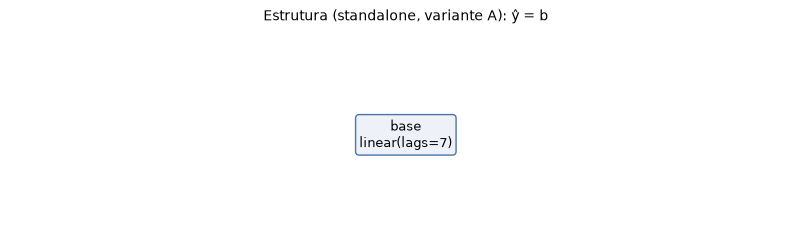

In [9]:
search.plot_model(result.best, "model_structure")

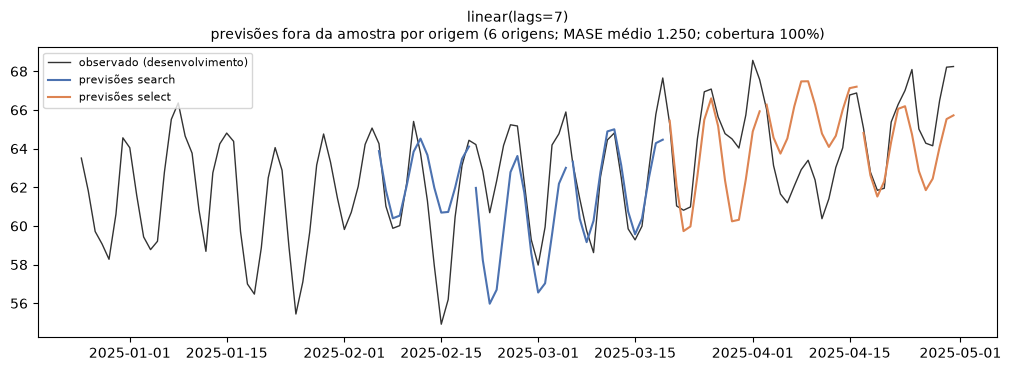

In [10]:
search.plot_model(result.best, "cv_forecasts")

## 5. Avaliação externa do campeão

Uma única leitura do teste selado, depois de congelar a escolha.

In [11]:
final = search.finalize_model(result.best)
search.evaluate_external(final).metrics.round(3)

,MASE,MAE,RMSE,sMAPE
model,,,,
linear(lags=7),1.109,1.736,2.043,0.027


## 6. Leitura

Nesta série (500 pontos, `fh=14`, 3 origens por camada):

* **Nenhuma agregação dos três membros superou o melhor membro** em `V_select`: `linear` sozinho tem MASE 1,28; o melhor ensemble (`inverse_mse`) fica em 1,34, e a média simples em 1,50. Os pesos aprendidos dão ~0,65 ao `linear` e quase não mudam entre origens — estáveis, mas ainda dividem peso com membros piores.
* Com 3 membros, `trimmed_mean` é igual à `median` (descarta um de cada ponta).
* O **ensemble de híbridos** (`nnls`, 1,33) ficou melhor que cada híbrido sozinho (1,41 e 1,34), sinal de alguma complementaridade entre as correções; o **ensemble corrigido** (1,64) ficou pior que o ensemble sem correção (1,50): aqui o corretor aprendeu ruído.
* **Custo:** um ensemble `nnls` de 3 membros ajusta 6 modelos por origem; o ensemble de dois híbridos, 12; o ensemble corrigido, 7.
* Na **busca**, o ensemble de híbridos venceu 2 de 3 unidades, mas com ganho mediano de 1,09%, abaixo do mínimo de 5%: recusado, e o `linear` ficou campeão (MASE 1,11 no teste selado). Com a regra anterior (ganho ≥ 1%) ele teria sido aceito — exatamente o tipo de aceite que a calibração mostrou ser frequente em séries sem estrutura a explorar (notebook 11, ADR-0008). Mesmo com a regra nova, `"ensemble"` fica fora do `include` padrão: ele ainda não passou pelo portão de calibração com essa regra.

Ensembles não são uma melhoria automática: o resultado depende dos membros, da série e de quantas origens sustentam a decisão.